# 04. 지속성 점검: 추천 3곳의 다음 1년 손님과 매출

- **목적**: `03`에서 고른 3곳의 다음 4개 분기(2026년 3분기 ~ 2027년 2분기) 월평균 결제 건수·매출 예측
- **검증할 가설**: H5 지속성: 추천 3곳의 손님과 매출은 다음 1년에도 유지된다 (이슈 트리 B 갈래 "앞으로도 매력적인가?")
- **방법**: 단순한 규칙 두 개를 과거 데이터로 시험해 보고(백테스트), 더 잘 맞은 규칙으로 예측
- **데이터 출처**: DB 표 `커피_매출`(2021년 1분기 ~ 2026년 2분기), `data/processed/추천_후보.csv` (`03` 출력)
- **출력**: `data/processed/예측_결과.csv`, `예측_백테스트.csv`, `docs/images/forecast_top3.png`

## 설정

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("..")  # notebooks/에서 실행하므로 프로젝트 루트의 src를 import 경로에 추가
from src.db import get_engine
from src.viz import quarter_label, set_korean_font

pd.set_option("display.max_columns", 30)
set_korean_font()

In [2]:
ENV_PATH = Path("../.env")
OUT_DIR = Path("../data/processed")
IMAGE_DIR = Path("../docs/images")

TARGETS = {"건수": "당월_매출_건수", "매출": "당월_매출_금액"}
UNIT = {"건수": (1e4, "결제 건수 (만 건)"), "매출": (1e8, "매출 (억 원)")}

# (규칙 이름, 성장률 반영 여부)
METHODS = {"작년 × (1 + 성장률)": True, "작년과 같음": False}
BACKTEST_ORIGINS = ["20232", "20242", "20252"]  # 각 분기까지만 안다고 가정하고 다음 4개 분기를 맞혀 봄
LATEST_QUARTER = "20262"
FUTURE_QUARTERS = ["20263", "20264", "20271", "20272"]

## 데이터 로드

In [3]:
engine = get_engine(ENV_PATH)
sales = pd.read_sql('SELECT * FROM "커피_매출"', engine)

# 상권 × 분기 표 (행 = 상권, 열 = 분기). pivot은 열을 분기 순서로 정렬함
pivots = {name: sales.pivot(index="상권_코드", columns="기준_년분기_코드", values=col) for name, col in TARGETS.items()}
quarters = list(pivots["건수"].columns)
print(quarters[0], "~", quarters[-1], len(quarters), "개 분기")

20211 ~ 20262 22 개 분기


In [4]:
candidates = pd.read_csv(OUT_DIR / "추천_후보.csv", dtype={"상권_코드": str}).set_index("상권_코드")
top3 = candidates.loc[candidates["추천"]].sort_values("점수", ascending=False)
names = top3["상권_코드_명"]
print("추천 3곳:", list(names))

추천 3곳: ['대치역', '방이역', '천호역']


## 1. 예측 규칙 두 개

예측 시점까지의 최근 4개 분기를 `최근 1년`, 그 앞 4개 분기를 `1년 전`이라고 할 때

| 규칙 | 다음 분기 예측 |
|---|---|
| 작년 × (1 + 성장률) | 1년 전 같은 분기 값 × (1 + g), g = `최근 1년` 합계 ÷ `1년 전` 합계 − 1 |
| 작년과 같음 | 1년 전 같은 분기 값 (g = 0) |

두 규칙 모두 1년 전 같은 분기 값에서 출발하므로 계절 효과(2분기 상승, 1분기 하락)가 그대로 들어감.
차이는 "지난 1년의 성장이 앞으로도 이어진다"고 볼지 여부.

In [5]:
def forecast_next_year(pivot: pd.DataFrame, origin: str, use_growth: bool) -> pd.DataFrame:
    """origin 분기까지의 값으로 다음 4개 분기를 예측함. 열은 '1년 전 같은 분기' 이름 그대로임."""
    i = quarters.index(origin)
    last_year = quarters[i - 3:i + 1]    # 최근 4개 분기 = 다음 4개 분기의 "1년 전 같은 분기"
    year_before = quarters[i - 7:i - 3]  # 그 앞 4개 분기
    growth = pivot[last_year].sum(axis=1) / pivot[year_before].sum(axis=1) - 1 if use_growth else 0
    return pivot[last_year].mul(1 + growth, axis=0)

## 2. 백테스트: 어느 규칙이 과거에 더 잘 맞았나

- 2023년 2분기, 2024년 2분기, 2025년 2분기까지만 안다고 가정하고 각각 다음 4개 분기를 예측한 뒤 실제 값과 비교
- 시점을 세 번 바꿔 보는 이유: 한 번만 하면 그해에만 우연히 잘 맞았을 수 있음
- 대상: 그 시점에 필요한 12개 분기(앞 8개 + 맞힐 4개) 값이 모두 있는 상권
- 오차율 = |예측 − 실제| ÷ 실제 × 100, 상권마다 4개 분기 평균(MAPE)
- 상권 몇 곳의 큰 오차가 평균을 끌어올리므로 상권들의 **중앙값**으로 비교

In [6]:
rows = []
for name, pivot in pivots.items():
    for origin in BACKTEST_ORIGINS:
        i = quarters.index(origin)
        data = pivot[quarters[i - 7:i + 5]].dropna()
        actual = data[quarters[i + 1:i + 5]]
        for method, use_growth in METHODS.items():
            pred = forecast_next_year(data, origin, use_growth)
            pred.columns = actual.columns  # "1년 전 같은 분기" 열 이름을 맞힐 분기 이름으로 바꿈
            mape = ((pred - actual).abs() / actual * 100).mean(axis=1)  # 상권별 4개 분기 평균 오차율
            for code, error in mape.items():
                rows.append({"대상": name, "예측 시점": origin, "규칙": method, "상권_코드": code, "오차율": error})

errors = pd.DataFrame(rows)
backtest = errors.pivot_table(index=["대상", "예측 시점"], columns="규칙", values="오차율", aggfunc="median")
backtest.round(1)

규칙        작년 × (1 + 성장률)  작년과 같음
대상 예측 시점                        
건수 20232            21.3    16.6
   20242            20.5    17.4
   20252            18.6    14.9
매출 20232            23.2    15.3
   20242            20.4    17.5
   20252            19.8    16.4

In [7]:
# 추천 3곳 각각의 오차율(세 시점 평균)
(errors.loc[errors["상권_코드"].isin(top3.index)]
 .pivot_table(index="상권_코드", columns=["대상", "규칙"], values="오차율", aggfunc="mean")
 .rename(index=names).round(1))

대상                건수                    매출       
규칙    작년 × (1 + 성장률) 작년과 같음 작년 × (1 + 성장률) 작년과 같음
상권_코드                                            
대치역             25.3   14.5           32.4   15.7
방이역             31.6   24.5           20.8   15.4
천호역             19.5   18.9           18.9   16.3

In [8]:
best_method = backtest.mean().idxmin()  # 6번(대상 2 × 시점 3)의 오차율 중앙값 평균이 가장 작은 규칙
print("더 잘 맞은 규칙:", best_method)

더 잘 맞은 규칙: 작년과 같음


### 관찰
- 6번의 비교(건수·매출 × 시점 3개) 모두 **"작년과 같음"이 더 잘 맞음**
  - 건수 오차율 중앙값: 16.6 / 17.4 / 14.9% vs 성장률 반영 21.3 / 20.5 / 18.6%
  - 매출 오차율 중앙값: 15.3 / 17.5 / 16.4% vs 성장률 반영 23.2 / 20.4 / 19.8%
- 추천 3곳도 세 곳 모두 "작년과 같음"의 오차가 더 작음(건수: 대치역 14.5%, 방이역 24.5%, 천호역 18.9%)
- 해석: 지난 1년 크게 오른 상권이 다음 해에도 같은 만큼 오르는 경우는 드묾 → 성장률을 그대로 이어 붙이면 과대 예측
- 가장 잘 맞은 규칙도 상권 하나의 오차가 보통 15 ~ 25% → 예측은 방향을 보는 참고 자료

## 3. 최종 예측: 2026년 3분기 ~ 2027년 2분기

- 2026년 2분기까지의 실제 값에 백테스트에서 이긴 규칙을 적용

In [9]:
forecasts = {}
for name, pivot in pivots.items():
    pred = forecast_next_year(pivot.loc[top3.index], LATEST_QUARTER, METHODS[best_method])
    pred.columns = FUTURE_QUARTERS
    forecasts[name] = pred

recent_quarters = quarters[-4:]
summary = pd.DataFrame([
    {
        "상권": names[code], "대상": name,
        "최근 1년 월평균": pivots[name].loc[code, recent_quarters].mean(),
        "다음 1년 월평균(예측)": forecasts[name].loc[code].mean(),
    }
    for code in top3.index for name in TARGETS
])
summary["예측 증가율(%)"] = (summary["다음 1년 월평균(예측)"] / summary["최근 1년 월평균"] - 1) * 100
summary.round(1)

,상권,대상,최근 1년 월평균,다음 1년 월평균(예측),예측 증가율(%)
0,대치역,건수,1.914658e+05,1.914658e+05,0.0
1,대치역,매출,9.172550e+08,9.172550e+08,0.0
2,방이역,건수,4.376675e+05,4.376675e+05,0.0
3,방이역,매출,1.833388e+09,1.833388e+09,0.0
4,천호역,건수,3.171482e+05,3.171482e+05,0.0
5,천호역,매출,1.662051e+09,1.662051e+09,0.0


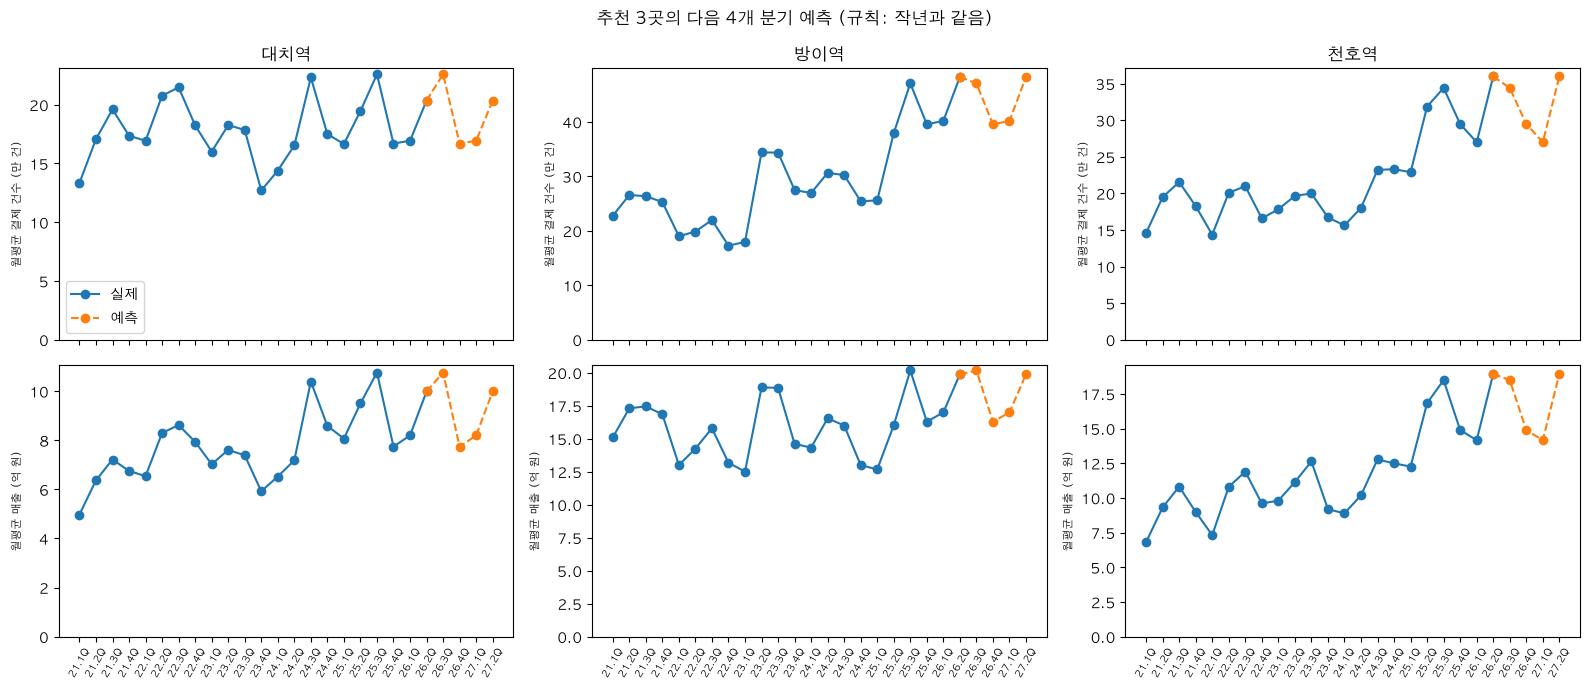

In [10]:
x_labels = [quarter_label(q) for q in quarters + FUTURE_QUARTERS]

fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
for col, code in enumerate(top3.index):
    for row, name in enumerate(TARGETS):
        divisor, label = UNIT[name]
        actual = pivots[name].loc[code, quarters] / divisor
        pred = forecasts[name].loc[code] / divisor
        ax = axes[row, col]
        ax.plot(x_labels[:len(quarters)], actual, marker="o", label="실제")
        # 마지막 실제 값과 예측을 선으로 이어 그림
        ax.plot(x_labels[len(quarters) - 1:], [actual.iloc[-1], *pred], marker="o", linestyle="--", label="예측")
        ax.set_ylim(bottom=0)
        ax.set_ylabel(f"월평균 {label}", fontsize=8)
        ax.tick_params(axis="x", labelrotation=60, labelsize=7)
    axes[0, col].set_title(names[code])
axes[0, 0].legend()
plt.suptitle(f"추천 3곳의 다음 4개 분기 예측 (규칙: {best_method})")
plt.tight_layout()
plt.savefig(IMAGE_DIR / "forecast_top3.png", dpi=150)
plt.show()

### 관찰
- 규칙이 "작년과 같음"이므로 다음 1년 월평균은 최근 1년 월평균과 같음(예측 증가율 0%)
  - 대치역: 월 19.1만 건, 9.2억 원 / 방이역: 월 43.8만 건, 18.3억 원 / 천호역: 월 31.7만 건, 16.6억 원
- 백테스트 오차를 생각하면 실제 값은 이보다 15 ~ 25% 높거나 낮을 수 있음
- 즉 "지난 2년 늘어난 손님이 다음 1년에도 유지된다"가 가장 근거 있는 예상
- 예측선은 최근 4개 분기의 계절 모양(3분기·2분기 높음, 4분기·1분기 낮음)을 그대로 반복함
- 대치역은 2026년 3분기(22.5만 건, 10.8억 원)가 가장 높고, 방이역·천호역 손님은 2027년 2분기가 가장 높게 예측됨

## 4. 결과 저장

In [11]:
forecast_long = pd.concat(
    [f.rename(index=names).stack().rename("예측").to_frame().assign(대상=name) for name, f in forecasts.items()]
).rename_axis(["상권", "분기"]).reset_index()
forecast_long.round(0).to_csv(OUT_DIR / "예측_결과.csv", index=False, encoding="utf-8")
backtest.round(2).to_csv(OUT_DIR / "예측_백테스트.csv", encoding="utf-8")
print("저장 완료")

저장 완료


## 결론과 다음 단계

**H5 판정: 채택(조건부).** 가장 잘 맞은 규칙으로 보면 세 곳 모두 최근 1년 수준이 유지되지만, 상권 하나의 오차가 15 ~ 25%라 방향만 믿을 수 있음

**모델 비교**
- 단순한 규칙 두 개를 세 시점에서 시험한 결과 "작년과 같음"이 매번 더 정확함(오차율 중앙값 15 ~ 17%)
- 지난 성장을 그대로 이어 붙이는 규칙은 오차율 중앙값이 약 3 ~ 8%p 더 큼

**예측 내용**
- 추천 3곳의 다음 1년 손님과 매출은 최근 1년 수준 유지(±15 ~ 25%)

**한계와 다음 단계**
- 규칙이 단순해서 새 카페 개업, 재개발 같은 상권 변화는 반영하지 못함
- 시험 시점이 3개뿐이라 오차 추정도 대략적인 값
- 다음 단계: 회귀분석처럼 다른 상권 정보를 함께 쓰는 방법을 시도하고, 같은 백테스트로 "작년과 같음"보다 나은지 확인